# 03 · Functional connectivity  (⏱ ~75 min)

**Concept:** brain regions whose signals rise and fall together are *functionally connected*. Compute a region-by-region matrix from the 2D signals you get out of a masker.

- **Correlation:** simple, but regions can look connected only via a third region.
- **Partial correlation / precision:** removes indirect links (needs enough time points; use shrinkage, e.g. `covariance_estimator=LedoitWolf()`, the default).
- **Tangent space:** often best for comparing groups/subjects or classification.

Tools: `nilearn.connectome.ConnectivityMeasure(kind=...)`, `plotting.plot_matrix`, `plotting.plot_connectome`.

**Gallery to read after your attempt (`03_connectivity`):** `plot_signal_extraction.py`, `plot_probabilistic_atlas_extraction.py`, `plot_inverse_covariance_connectome.py`, `plot_group_level_connectivity.py` (compares `kind=` options and groups, close to Ex 5), `plot_seed_to_voxel_correlation.py` and `plot_sphere_based_connectome.py` (Ex 6).

In [1]:
!pip install -q nilearn
import nilearn, numpy as np, pandas as pd, matplotlib.pyplot as plt
print("nilearn", nilearn.__version__)

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires pandas==2.2.3, but you have pandas 3.1.0 which is incompatible.
google-colab 1.0.0 requires requests==2.32.4, but you have requests 2.34.2 which is incompatible.
nilearn 0.14.1


/usr/local/lib/python3.13/dist-packages/pandas/core/arrays/masked.py:63: UserWarning: Pandas requires version '1.5.0' or newer of 'bottleneck' (version '1.4.2' currently installed).
  from pandas.core import (


**Data tip:** nilearn downloads datasets to `~/nilearn_data`, which Colab wipes when the runtime resets.
If you don't want to re-download, mount Drive and pass `data_dir=` to the `fetch_*` functions
(`from google.colab import drive; drive.mount('/content/drive')`).

In [2]:
from nilearn import datasets, maskers, plotting, connectome
dev = datasets.fetch_development_fmri(n_subjects=10)   # children + adults, with confounds
print(dev.keys())
print(dev.phenotypic.head())
msdl = datasets.fetch_atlas_msdl()   # probabilistic maps with region coordinates

[fetch_development_fmri] Added README.md to /root/nilearn_data

[fetch_development_fmri] Dataset created in /root/nilearn_data/development_fmri

[fetch_development_fmri] Downloading data from https://osf.io/yr3av/download ...

[fetch_development_fmri]  ...done. (3 seconds, 0 min)

[fetch_development_fmri] Downloading data from https://osf.io/download/5c8ff3df4712b400183b7092/ ...

[fetch_development_fmri]  ...done. (2 seconds, 0 min)

... (40 outputs left out)

[fetch_atlas_msdl] Downloading data from https://team.inria.fr/parietal/files/2015/01/MSDL_rois.zip ...

[fetch_atlas_msdl]  ...done. (1 seconds, 0 min)

[fetch_atlas_msdl] Extracting data from /root/nilearn_data/msdl_atlas/e79625f201e60c733df1b1ddd19a0427/MSDL_rois.zip...

[fetch_atlas_msdl] .. done.

## Exercises
- **Ex 1.** For *one* subject, use a `NiftiMapsMasker` with `msdl.maps`, `standardize`, `detrend`, the dataset's own `dev.t_r`, and that subject's confounds (`dev.confounds[0]`). Get the time series matrix. (The confounds file has many columns; the gallery's `plot_signal_extraction.py` shows how to select a reduced set. Try to work out which columns you'd want first.)
- **Ex 2.** Compute a correlation matrix with `ConnectivityMeasure(kind="correlation")`. Plot with `plotting.plot_matrix` (try `labels=`, `reorder=True`). Note: `fit_transform` wants a *list* of subjects' matrices. Why a list?
- **Ex 3.** Repeat with `kind="partial correlation"`. *Predict*: will the matrix be denser or sparser than plain correlation? Why?
- **Ex 4.** Visualise the strongest connections on a glass brain with `plotting.plot_connectome` (`msdl.region_coords`, `edge_threshold="90%"`).
- **Ex 5 (group).** Loop over all subjects, build the list of time series, and compute a *mean* connectivity matrix per age group using the `Child_Adult` column of `dev.phenotypic`. Plot child minus adult. What would you need before claiming a group difference is real?
- **Ex 6 (stretch).** Seed-to-voxel: build a `NiftiSpheresMasker` at a posterior cingulate coordinate (e.g. `(0, -52, 18)`), correlate its time series with a whole-brain `NiftiMasker`, map back with `inverse_transform`, and plot. This is the classic "default mode network" demo.

In [20]:
nilearn.interfaces.fmriprep.load_confounds_utils.load_confounds_file_as_dataframe(dev.confounds[0])

,trans_x,trans_y,trans_z,rot_x,rot_y,rot_z,framewise_displacement,a_comp_cor_00,a_comp_cor_01,a_comp_cor_02,a_comp_cor_03,a_comp_cor_04,a_comp_cor_05,csf,white_matter
0,-0.000233,-0.076885,0.062321,7.322780e-04,0.000352,0.000841,0.000000,-0.099871,-0.007286,0.001780,-0.008073,0.030945,-0.022393,439.699409,451.645460
1,-0.006187,-0.078395,0.056773,1.122190e-04,0.000187,0.000775,0.055543,-0.019437,-0.042308,0.016735,-0.012099,0.088777,-0.006171,439.471640,451.103437
2,-0.000227,-0.069893,0.083102,1.434700e-04,0.000364,0.000716,0.054112,0.009096,-0.053206,-0.030388,-0.052925,0.019922,0.014776,439.744498,450.981505
3,0.002492,-0.074707,0.060337,2.016850e-04,0.000818,0.000681,0.057667,0.060195,-0.083195,0.003578,-0.037011,0.026946,0.002505,440.772620,450.600261
4,-0.000226,-0.084204,0.085079,1.834170e-04,0.000548,0.000682,0.051438,0.049833,-0.089819,-0.020825,-0.079329,0.008516,-0.000938,440.115442,450.678959
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
163,-0.017332,0.014066,-0.014854,1.288150e-04,-0.000566,0.000916,0.238491,-0.012716,0.056354,0.015468,-0.018283,0.069908,-0.015623,444.820171,453.743564
164,-0.019105,-0.115073,-0.034933,8.338870e-04,-0.000510,0.000633,0.203179,0.026579,0.113651,-0.025939,0.006790,-0.056386,-0.143115,444.618416,453.760129
165,-0.011159,0.002433,-0.022185,2.650120e-04,-0.000805,0.000731,0.186323,-0.084232,0.140013,0.041006,-0.022548,0.045866,0.035185,445.764668,454.113252
166,-0.015082,-0.132366,-0.026921,1.284910e-03,-0.000788,0.000686,0.197564,-0.002535,0.201289,-0.041035,0.016435,-0.121567,0.069279,445.859847,453.644592


In [14]:
maps_masker = maskers.NiftiMapsMasker(msdl.maps, standardize=True, detrend=True,
                                       t_r=dev.t_r)
subject_1_x = maps_masker.fit_transform(dev.func[0], confounds=dev.confounds[0])

/tmp/ipykernel_1616/1231546662.py:3: FutureWarning: boolean values for 'standardize' will be deprecated in nilearn 0.15.0.
Use 'zscore_sample' instead of 'True' or use 'None' instead of 'False'.
  subject_1_x = maps_masker.fit_transform(dev.func[0], confounds=dev.confounds[0])
/tmp/ipykernel_1616/1231546662.py:3: FutureWarning: boolean values for 'standardize' will be deprecated in nilearn 0.15.0.
Use 'zscore_sample' instead of 'True' or use 'None' instead of 'False'.
  subject_1_x = maps_masker.fit_transform(dev.func[0], confounds=dev.confounds[0])


In [15]:
subject_1_x.shape

(168, 39)

- **Ex 2.** Compute a correlation matrix with `ConnectivityMeasure(kind="correlation")`. Plot with `plotting.plot_matrix` (try `labels=`, `reorder=True`). Note: `fit_transform` wants a *list* of subjects' matrices. Why a list?

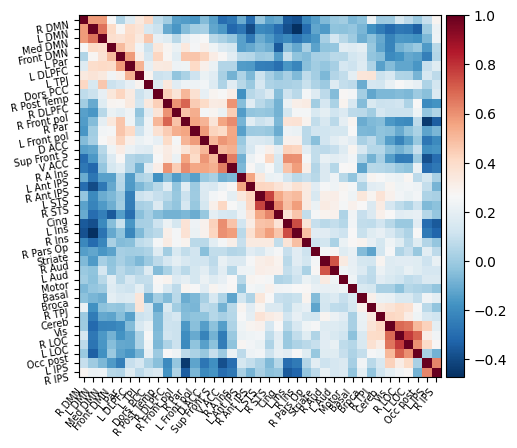

In [28]:
correl_matrix = connectome.ConnectivityMeasure(kind="correlation").fit_transform([subject_1_x])
plotting.plot_matrix(correl_matrix[0], labels=msdl.labels, reorder=True)
#It wants a list of subject matrices because you may want create correllation grids for multiple subjects at a time

- **Ex 3.** Repeat with `kind="partial correlation"`. *Predict*: will the matrix be denser or sparser than plain correlation? Why?


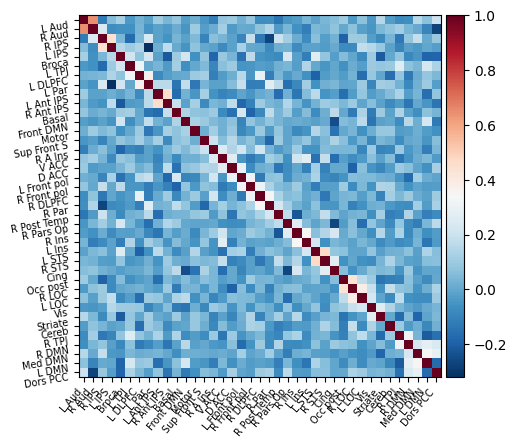

In [30]:
correl_matrix = connectome.ConnectivityMeasure(kind="partial correlation").fit_transform([subject_1_x])
plotting.plot_matrix(correl_matrix[0], labels=msdl.labels, reorder=True)

- **Ex 4.** Visualise the strongest connections on a glass brain with `plotting.plot_connectome` (`msdl.region_coords`, `edge_threshold="90%"`).


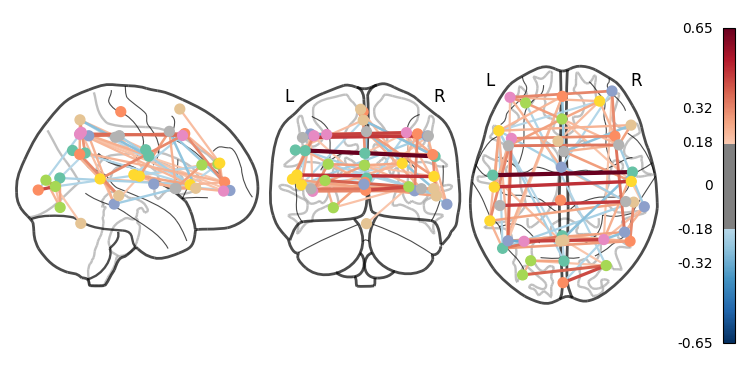

In [31]:
plotting.plot_connectome(correl_matrix[0], msdl.region_coords, edge_threshold="90%")

- **Ex 5 (group).** Loop over all subjects, build the list of time series, and compute a *mean* connectivity matrix per age group using the `Child_Adult` column of `dev.phenotypic`. Plot child minus adult. What would you need before claiming a group difference is real?


In [86]:
list_of_subjects = dev.phenotypic['participant_id']
loop_counter = 0

adult_correl_matrix = []
child_correl_matrix = []

for subject_index in list_of_subjects.keys():
  print(subject_index)
  subject_x = maps_masker.fit_transform(dev.func[loop_counter], confounds=dev.confounds[loop_counter])
  correl_matrix = connectome.ConnectivityMeasure(kind="correlation").fit_transform([subject_x])
  if dev.phenotypic['Child_Adult'][subject_index] == 'adult':
    adult_correl_matrix.append(correl_matrix[0])
  else:
    child_correl_matrix.append(correl_matrix[0])
  loop_counter += 1

122


/tmp/ipykernel_1616/1959792922.py:9: FutureWarning: boolean values for 'standardize' will be deprecated in nilearn 0.15.0.
Use 'zscore_sample' instead of 'True' or use 'None' instead of 'False'.
  subject_x = maps_masker.fit_transform(dev.func[loop_counter], confounds=dev.confounds[loop_counter])
/tmp/ipykernel_1616/1959792922.py:9: FutureWarning: boolean values for 'standardize' will be deprecated in nilearn 0.15.0.
Use 'zscore_sample' instead of 'True' or use 'None' instead of 'False'.
  subject_x = maps_masker.fit_transform(dev.func[loop_counter], confounds=dev.confounds[loop_counter])


123


/tmp/ipykernel_1616/1959792922.py:9: FutureWarning: boolean values for 'standardize' will be deprecated in nilearn 0.15.0.
Use 'zscore_sample' instead of 'True' or use 'None' instead of 'False'.
  subject_x = maps_masker.fit_transform(dev.func[loop_counter], confounds=dev.confounds[loop_counter])
/tmp/ipykernel_1616/1959792922.py:9: FutureWarning: boolean values for 'standardize' will be deprecated in nilearn 0.15.0.
Use 'zscore_sample' instead of 'True' or use 'None' instead of 'False'.
  subject_x = maps_masker.fit_transform(dev.func[loop_counter], confounds=dev.confounds[loop_counter])


0


/tmp/ipykernel_1616/1959792922.py:9: FutureWarning: boolean values for 'standardize' will be deprecated in nilearn 0.15.0.
Use 'zscore_sample' instead of 'True' or use 'None' instead of 'False'.
  subject_x = maps_masker.fit_transform(dev.func[loop_counter], confounds=dev.confounds[loop_counter])
/tmp/ipykernel_1616/1959792922.py:9: FutureWarning: boolean values for 'standardize' will be deprecated in nilearn 0.15.0.
Use 'zscore_sample' instead of 'True' or use 'None' instead of 'False'.
  subject_x = maps_masker.fit_transform(dev.func[loop_counter], confounds=dev.confounds[loop_counter])


... (10 outputs left out)

6


/tmp/ipykernel_1616/1959792922.py:9: FutureWarning: boolean values for 'standardize' will be deprecated in nilearn 0.15.0.
Use 'zscore_sample' instead of 'True' or use 'None' instead of 'False'.
  subject_x = maps_masker.fit_transform(dev.func[loop_counter], confounds=dev.confounds[loop_counter])
/tmp/ipykernel_1616/1959792922.py:9: FutureWarning: boolean values for 'standardize' will be deprecated in nilearn 0.15.0.
Use 'zscore_sample' instead of 'True' or use 'None' instead of 'False'.
  subject_x = maps_masker.fit_transform(dev.func[loop_counter], confounds=dev.confounds[loop_counter])


7


/tmp/ipykernel_1616/1959792922.py:9: FutureWarning: boolean values for 'standardize' will be deprecated in nilearn 0.15.0.
Use 'zscore_sample' instead of 'True' or use 'None' instead of 'False'.
  subject_x = maps_masker.fit_transform(dev.func[loop_counter], confounds=dev.confounds[loop_counter])
/tmp/ipykernel_1616/1959792922.py:9: FutureWarning: boolean values for 'standardize' will be deprecated in nilearn 0.15.0.
Use 'zscore_sample' instead of 'True' or use 'None' instead of 'False'.
  subject_x = maps_masker.fit_transform(dev.func[loop_counter], confounds=dev.confounds[loop_counter])


In [93]:
adult_correl_matrix = np.array(adult_correl_matrix)
child_correl_matrix = np.array(child_correl_matrix)

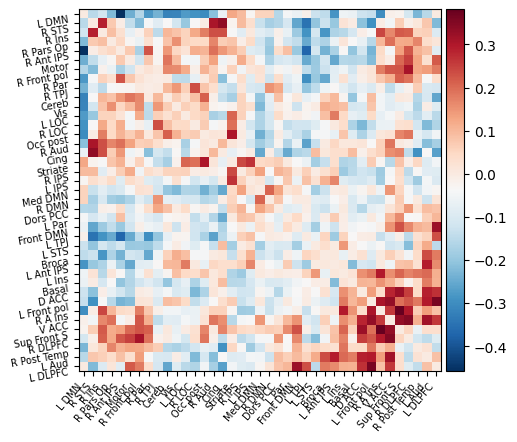

In [98]:
mean_adult = np.mean(adult_correl_matrix, axis=0)
mean_child = np.mean(child_correl_matrix, axis=0)
plotting.plot_matrix(mean_adult - mean_child, labels=msdl.labels, reorder=True)
#A larger dataset rather than just 2 and 8 subjects would be nice. This plot
#shows what regions have the biggest difference in correlation between adults and children.
#I guess what I would be looking for is the largest differences in correlation to show a
#difference between groups.

- **Ex 6 (stretch).** Seed-to-voxel: build a `NiftiSpheresMasker` at a posterior cingulate coordinate (e.g. `(0, -52, 18)`), correlate its time series with a whole-brain `NiftiMasker`, map back with `inverse_transform`, and plot. This is the classic "default mode network" demo.

## Check your understanding
- Why do connectivity results depend so much on motion confounds?  
A: Motion shows up as correlation across all voxels/regions, and thus needs to be accounted for.
- What problem does shrinkage solve when time points are few relative to regions?  
A: With relatively few time points, estimates are less reliable. Thus shrinkage tempers estimates by pulling estimates towards a more reasonable baseline.
- Why is it risky to draw group conclusions from 10 subjects?  
A: With so few subjects, you have a very large room for error. Just one subject with an "erroneous" result can sway the whole of the conclusion. Especially here with only 8 children and 2 adults, if just one adult has out of the ordinary results, it would greatly sway any calculations relying on only the adult dataset.

## Industry/research angle
Connectivity features are used in psychiatric/neurological biomarker research (e.g. ADHD, autism, depression, Alzheimer's studies) and as inputs to classifiers; the pitfalls above are why reproducibility is a big topic in this field.